# 02 · H1: влияние настройки гиперпараметров

**Цель:** проверить, изменяет ли подбор гиперпараметров качество прогнозирования Logistic Regression, Random Forest, XGBoost и MLP по сравнению с исходными (неоптимизированными) конфигурациями.

**Гипотеза H1:** «Подбор гиперпараметров может улучшить качество прогнозирования моделей машинного обучения по сравнению с их настройками по умолчанию».

В этом ноутбуке для каждой модели сравниваются **два варианта**: исходная конфигурация и конфигурация, выбранная через кросс-валидацию **исключительно на train**. Модель PLCOm2012 приводится только как неизменяемый контрольный ориентир: у неё нет подбираемых здесь параметров.

Используем **новую синтетическую генерацию**, отличную от `01_baseline.ipynb`, чтобы повторно не опираться на уже просмотренный в предыдущем эксперименте test. В пределах этого эксперимента у всех методов одинаковые наблюдения. Исход по-прежнему задаётся `Bernoulli(PLCOm2012(X))`, поэтому контрольный сценарий **не предполагает обязательного выигрыша обучаемых моделей**.

Общие правила: [протокол](../docs/experiment_protocol.md) · [гипотезы](../docs/hypotheses.md).

## 1. Среда и импорты

Используем `lung-cancer-ml`, модули `src/` из шестого коммита и XGBoost из восьмого. Ноутбук можно запустить из корня репозитория или папки `notebooks/`.

In [39]:
from pathlib import Path
import json
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import xgboost
from IPython.display import Markdown, display
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'src' / 'data_generation.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Запустите ноутбук из каталога репозитория или notebooks/')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_generation import generate_baseline
from src.evaluation import evaluate_binary, select_threshold_at_specificity
from src.plco import plco_risk
from src.preprocessing import FEATURE_COLUMNS, make_preprocessor, split_dataset

print('Корень проекта:', PROJECT_ROOT)
print('Python:', sys.version.split()[0], '|', sys.executable)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('SciPy:', scipy.__version__, '| scikit-learn:', sklearn.__version__)
print('XGBoost:', xgboost.__version__)

Корень проекта: /Users/dyadyundanil/Documents/lung-cancer-ml-study
Python: 3.11.11 | /opt/anaconda3/envs/lung-cancer-ml/bin/python
NumPy: 2.4.6 | pandas: 3.1.1
SciPy: 1.17.1 | scikit-learn: 1.9.1
XGBoost: 3.2.0


## 2. Конфигурация эксперимента

- `N=50_000`, стратифицированное разделение train/validation/test = 60/20/20.
- **Внутренняя 3-fold stratified CV** проводится только на train. Преобразования внутри `Pipeline` каждый раз подгоняются заново по обучающей части фолда.
- Оцениваем **6 случайных конфигураций** для каждого алгоритма; пространства поиска и число попыток зафиксированы до оценки на test.
- **Критерий подбора:** стандартизованная частичная ROC AUC в области FPR ≤ 0,10. Она согласована с интересом к высокой специфичности, но **не тождественна** Recall при выбранном пороге.
- Validation используется исключительно для выбора порога каждой уже обученной модели при Specificity ≥ 90%; test — только для итогового отчёта.

Здесь используется *holdout test + внутренняя CV*, а **не nested CV**. Для одного фиксированного test это корректная схема, если не принимать последующих решений на основании его результатов; устойчивость выводов оценим в H4.

In [42]:
N = 50_000
DATA_SEED = 314159           # Отличается от seed=42 в 01_baseline
SPLIT_SEED = 271828          # Отличается от seed=123 в 01_baseline
MODEL_SEED = 2026
CV_SEED = 1729
N_SPLITS = 3
N_ITER = 6
MIN_SPECIFICITY = 0.90
SEARCH_N_JOBS = 1            # Избегаем вложенного параллелизма
ESTIMATOR_N_JOBS = 2

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=CV_SEED)
pauc_scorer = make_scorer(
    roc_auc_score, response_method='predict_proba', max_fpr=0.10,
)

print(f'CV: {N_SPLITS} фолда; {N_ITER} конфигураций на модель')

CV: 3 фолда; 6 конфигураций на модель


## 3. Генерация и разбиение

**Не допускаем утечки:** `risk`, `logit_base`, `logit_true`, `y` не входят в признаки. После разбиения никаких строк из validation или test не используем для обучения или подбора параметров.

In [45]:
df = generate_baseline(n=N, seed=DATA_SEED)
splits = split_dataset(df, val_fraction=0.20, test_fraction=0.20, seed=SPLIT_SEED)

assert list(splits.X_train.columns) == list(FEATURE_COLUMNS)
assert not {'risk', 'logit_base', 'logit_true', 'y'} & set(splits.X_train.columns)
train_ids, val_ids, test_ids = (set(x.index) for x in (
    splits.X_train, splits.X_val, splits.X_test
))
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

split_table = pd.DataFrame({
    'Часть': ['Train', 'Validation', 'Test'],
    'Наблюдений': [len(splits.y_train), len(splits.y_val), len(splits.y_test)],
    'Положительных': [int(splits.y_train.sum()), int(splits.y_val.sum()), int(splits.y_test.sum())],
    'Доля y=1, %': [100 * y.mean() for y in (
        splits.y_train, splits.y_val, splits.y_test
    )],
}).set_index('Часть')
display(split_table.round(3))
print('Средний истинный риск, %:', round(100 * df.risk.mean(), 3))
print('Признаков:', len(FEATURE_COLUMNS))

,Наблюдений,Положительных,"Доля y=1, %"
Часть,,,
Train,30000,250,0.833
Validation,10000,83,0.830
Test,10000,84,0.840


Средний истинный риск, %: 0.835
Признаков: 11


## 4. Исходные модели и пространства поиска

**Исходная конфигурация** — библиотечные значения по умолчанию для гиперпараметров, влияющих на гибкость модели. Явно задаём `random_state`, количество потоков и технические параметры: у Logistic Regression повышаем `max_iter` до 1000 для сходимости, а для XGBoost фиксируем `objective`, `eval_metric` и `tree_method`.

Это **не** набор фиксированных гиперпараметров из `01_baseline.ipynb`: там уже задавались конкретные глубины деревьев, архитектура MLP и т. п. Поэтому численные результаты ноутбуков нельзя напрямую считать эффектом настройки: сравнение «исходная против настроенной» проводится **внутри текущего эксперимента**.

Для честной оценки Brier score не вводим `class_weight='balanced'` и `scale_pos_weight`: они могут изменить калибровку вероятностей. Пространства поиска намеренно ограничены вычислительным бюджетом — найденные параметры не считаем глобально оптимальными.

In [48]:
def build_pipeline(estimator):
    return Pipeline([
        ('preprocessor', make_preprocessor()),
        ('model', estimator),
    ])

initial_models = {
    'Logistic Regression': build_pipeline(
        LogisticRegression(max_iter=1000, random_state=MODEL_SEED)
    ),
    'Random Forest': build_pipeline(
        RandomForestClassifier(random_state=MODEL_SEED, n_jobs=ESTIMATOR_N_JOBS)
    ),
    'XGBoost': build_pipeline(
        XGBClassifier(
            objective='binary:logistic', eval_metric='logloss',
            tree_method='hist', n_jobs=ESTIMATOR_N_JOBS,
            random_state=MODEL_SEED,
        )
    ),
    'MLP': build_pipeline(
        MLPClassifier(random_state=MODEL_SEED)
    ),
}

search_spaces = {
    'Logistic Regression': {
        'model__C': [0.01, 0.03, 0.1, 0.3, 3.0, 10.0, 30.0],
    },
    'Random Forest': {
        'model__n_estimators': [120, 220, 320],
        'model__max_depth': [None, 8, 14],
        'model__min_samples_leaf': [2, 6, 15],
        'model__max_features': ['sqrt', 0.7],
    },
    'XGBoost': {
        'model__n_estimators': [100, 200, 320],
        'model__max_depth': [2, 3, 5],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__min_child_weight': [1, 5, 15],
        'model__subsample': [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0],
    },
    'MLP': {
        'model__hidden_layer_sizes': [(24,), (48,), (32, 16)],
        'model__alpha': [0.0001, 0.001, 0.01, 0.1],
        'model__learning_rate_init': [0.0005, 0.001, 0.003],
    },
}

assert set(initial_models) == set(search_spaces)
print('Алгоритмы:', ', '.join(initial_models))

Алгоритмы: Logistic Regression, Random Forest, XGBoost, MLP


## 5. Внутренняя CV: сравнение и подбор гиперпараметров

Для каждого алгоритма:

1. Оценим исходную конфигурацию по трём train-фолдам.
2. Выполним `RandomizedSearchCV` по тому же трёхфолдному разбиению, выбирая параметры по средней partial ROC AUC (FPR ≤0,10).
3. Сравним лучший результат поиска со средним CV-результатом исходной модели **на тех же фолдах**. Если поиск не дал улучшения, **оставим исходную конфигурацию**. Это правило фиксируется заранее, без validation и test.
4. `refit=True` обучит лучшую найденную конфигурацию на **всём train**; исходную конфигурацию также обучаем на всём train.

**Важно:** максимальное CV-значение после поиска имеет оптимистическое смещение из-за выбора лучшей конфигурации. Поэтому оно не служит окончательным доказательством улучшения. Итоговое сравнение будет на test, который здесь не используется.

Выполнение может занять несколько минут, особенно для MLP. При предупреждениях о сходимости MLP не скрываем их и учитываем в выводах.

In [51]:
fitted_initial = {}
fitted_tuned = {}
searches = {}
search_rows = []
selected_params = {}

for i, (name, initial) in enumerate(initial_models.items()):
    started = time.perf_counter()
    print(f'\n{name}: CV исходной конфигурации...')
    initial_cv = cross_val_score(
        initial, splits.X_train, splits.y_train,
        cv=cv, scoring=pauc_scorer, n_jobs=SEARCH_N_JOBS,
        error_score='raise',
    )

    print(f'{name}: RandomizedSearchCV ({N_ITER} × {N_SPLITS})...')
    search = RandomizedSearchCV(
        estimator=initial,
        param_distributions=search_spaces[name],
        n_iter=N_ITER,
        scoring=pauc_scorer,
        cv=cv,
        n_jobs=SEARCH_N_JOBS,
        random_state=MODEL_SEED + i,
        refit=True,
        error_score='raise',
        return_train_score=False,
    )
    search.fit(splits.X_train, splits.y_train)
    searches[name] = search
    # Исходная модель обучается на тех же 60% данных для честного сравнения.
    initial.fit(splits.X_train, splits.y_train)
    fitted_initial[name] = initial

    # Выбираем между исходной и найденной конфигурацией по СТРОГО train-CV.
    keep_initial = float(initial_cv.mean()) >= float(search.best_score_)
    fitted_tuned[name] = initial if keep_initial else search.best_estimator_
    selected_params[name] = {} if keep_initial else search.best_params_
    selected_cv_score = (float(initial_cv.mean()) if keep_initial
                         else float(search.best_score_))

    elapsed = time.perf_counter() - started
    search_rows.append({
        'Модель': name,
        'CV pAUC (исходная)': float(initial_cv.mean()),
        'CV pAUC std (исходная)': float(initial_cv.std(ddof=1)),
        'CV pAUC (лучший поиск)': float(search.best_score_),
        'CV pAUC (выбранная)': selected_cv_score,
        'Итог настройки': 'оставлена исходная' if keep_initial else 'выбрана новая',
        'Время CV + обучение, c': elapsed,
        'Выбранные параметры': selected_params[name],
    })
    print(f'Готово за {elapsed:.1f} с; CV pAUC: '
          f'{initial_cv.mean():.4f} → {selected_cv_score:.4f}; '
          f'выбор: {"исходная" if keep_initial else "новая"}')

search_table = pd.DataFrame(search_rows).set_index('Модель')
display(search_table.round(4))


Logistic Regression: CV исходной конфигурации...
Logistic Regression: RandomizedSearchCV (6 × 3)...
Готово за 0.6 с; CV pAUC: 0.6308 → 0.6308; выбор: новая

Random Forest: CV исходной конфигурации...
Random Forest: RandomizedSearchCV (6 × 3)...
Готово за 26.3 с; CV pAUC: 0.5795 → 0.6074; выбор: новая

XGBoost: CV исходной конфигурации...
XGBoost: RandomizedSearchCV (6 × 3)...
Готово за 2.8 с; CV pAUC: 0.5655 → 0.6183; выбор: новая

MLP: CV исходной конфигурации...


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP: RandomizedSearchCV (6 × 3)...
Готово за 69.0 с; CV pAUC: 0.5688 → 0.6259; выбор: новая


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,CV pAUC (исходная),CV pAUC std (исходная),CV pAUC (лучший поиск),CV pAUC (выбранная),Итог настройки,"Время CV + обучение, c",Выбранные параметры
Модель,,,,,,,
Logistic Regression,0.6308,0.0452,0.6308,0.6308,выбрана новая,0.5875,{'model__C': 3.0}
Random Forest,0.5795,0.0143,0.6074,0.6074,выбрана новая,26.3271,"{'model__n_estimators': 120, 'model__min_sampl..."
XGBoost,0.5655,0.0241,0.6183,0.6183,выбрана новая,2.7727,"{'model__subsample': 1.0, 'model__n_estimators..."
MLP,0.5688,0.0134,0.6259,0.6259,выбрана новая,69.0245,"{'model__learning_rate_init': 0.001, 'model__h..."


### Краткая интерпретация CV

Если найденные значения `CV pAUC (лучший поиск)` выше, это **ожидаемый результат оптимизации по той же CV**. Сам по себе он не означает улучшения на новых данных: при шести попытках мы выбираем наилучший из шумных результатов. Если **исходная модель по CV лучше**, итоговый вариант «после настройки» остаётся неизменным (это отражено в таблице). Проверять H1 будем по независимому test.

<!-- h1-results-comment:5 -->
### Результаты блока 5: подбор гиперпараметров

**Вывод.** Средняя CV pAUC увеличилась у Random Forest (0.5795 → 0.6074), XGBoost (0.5655 → 0.6183) и MLP (0.5688 → 0.6259). У Logistic Regression результат практически не изменился (0.6308 → 0.6308 при округлении). Наибольший прирост на CV получила MLP, но её настройка заняла больше всего времени. Поскольку параметры выбраны по той же CV, окончательный эффект оцениваем на test.


## 6. Validation: фиксируем пороги без обращения к test

Для каждого варианта каждой модели выбираем **собственный** порог при Specificity(validation) ≥ 90%. Разные числовые пороги нормальны: распределения прогнозируемых вероятностей различаются.

Таблица ниже показывает только валидационные результаты; **тестовые метки пока не используются**.

In [58]:
all_models = {'PLCOm2012': None}
for name in initial_models:
    all_models[f'{name} · исходная'] = fitted_initial[name]
    all_models[f'{name} · настроенная'] = fitted_tuned[name]

val_probabilities = {}
thresholds = {}
val_rows = []

for label, model in all_models.items():
    probs = (splits.X_val.apply(plco_risk, axis=1).to_numpy()
             if model is None else model.predict_proba(splits.X_val)[:, 1])
    assert np.isfinite(probs).all() and ((probs >= 0) & (probs <= 1)).all()
    val_probabilities[label] = probs
    threshold = select_threshold_at_specificity(
        splits.y_val, probs, min_specificity=MIN_SPECIFICITY,
    )
    thresholds[label] = threshold
    metrics = evaluate_binary(splits.y_val, probs, threshold=threshold)
    assert metrics['specificity'] >= MIN_SPECIFICITY - 1e-12
    val_rows.append({
        'Вариант': label,
        'Порог': threshold,
        'Specificity (val)': metrics['specificity'],
        'Recall (val)': metrics['recall'],
        'TP (val)': metrics['tp'],
        'FP (val)': metrics['fp'],
    })

validation_table = pd.DataFrame(val_rows).set_index('Вариант')
display(validation_table.round(5))

,Порог,Specificity (val),Recall (val),TP (val),FP (val)
Вариант,,,,,
PLCOm2012,0.02379,0.90007,0.55422,46,991
Logistic Regression · исходная,0.01642,0.90007,0.51807,43,991
Logistic Regression · настроенная,0.01633,0.90007,0.51807,43,991
Random Forest · исходная,0.04000,0.91933,0.31325,26,800
Random Forest · настроенная,0.02344,0.90007,0.42169,35,991
XGBoost · исходная,0.01251,0.90007,0.28916,24,991
XGBoost · настроенная,0.02084,0.90007,0.43373,36,991
MLP · исходная,0.01675,0.90007,0.37349,31,991
MLP · настроенная,0.02115,0.90007,0.48193,40,991


<!-- h1-results-comment:6 -->
### Результаты блока 6: выбор порога на validation

**Вывод.** Для большинства вариантов достигнута Specificity(validation) ≈ 90.01%. У исходной Random Forest она составила 91.93%: из-за дискретных значений вероятностей порог нельзя было подобрать ближе к ограничению. После настройки Recall(validation) увеличился у Random Forest, XGBoost и MLP; у Logistic Regression остался 51.81%. Все пороги зафиксированы **до оценки на test**.


## 7. Окончательная оценка на test — однократно

**До этой ячейки** уже зафиксированы пространства поиска, лучшая конфигурация каждой модели и её порог. Теперь вычисляем предсказания для test **один раз**, не меняя ничего на основании результата.

Сравниваем Recall при пороге, выбранном на validation, фактическую Specificity(test), pAUC (FPR≤0,10), ROC AUC, AP и Brier. Интервалы Уилсона для Recall отражают только неопределённость при данном числе положительных исходов; они не включают изменчивость обучения и генерации данных.

In [62]:
test_probabilities = {}
test_metrics = {}
report_rows = []

for label, model in all_models.items():
    probs = (splits.X_test.apply(plco_risk, axis=1).to_numpy()
             if model is None else model.predict_proba(splits.X_test)[:, 1])
    test_probabilities[label] = probs
    m = evaluate_binary(splits.y_test, probs, threshold=thresholds[label])
    test_metrics[label] = m
    ci = binomtest(m['tp'], m['positives']).proportion_ci(
        confidence_level=0.95, method='wilson',
    )
    report_rows.append({
        'Вариант': label,
        'Recall (test)': m['recall'],
        'Recall 95% CI': f'[{ci.low:.3f}; {ci.high:.3f}]',
        'Specificity (test)': m['specificity'],
        'pAUC std (FPR≤0.10)': m['pauc_standardized_fpr_0_10'],
        'ROC AUC': m['roc_auc'],
        'AP': m['average_precision'],
        'Brier': m['brier_score'],
        'TP': m['tp'], 'FP': m['fp'],
        'FN': m['fn'], 'TN': m['tn'],
        'Threshold': m['threshold'],
    })

report = pd.DataFrame(report_rows).set_index('Вариант')
display(report.round(5))
print('Положительных случаев на test:', int(splits.y_test.sum()))
print('Specificity(test) может оказаться ниже 90%: пороги на test не перенастраиваются.')

,Recall (test),Recall 95% CI,Specificity (test),pAUC std (FPR≤0.10),ROC AUC,AP,Brier,TP,FP,FN,TN,Threshold
Вариант,,,,,,,,,,,,
PLCOm2012,0.57143,[0.465; 0.672],0.90188,0.67316,0.87353,0.08239,0.00806,48,973,36,8943,0.02379
Logistic Regression · исходная,0.55952,[0.453; 0.661],0.90510,0.66254,0.83648,0.06603,0.00810,47,941,37,8975,0.01642
Logistic Regression · настроенная,0.57143,[0.465; 0.672],0.90409,0.66277,0.83653,0.06665,0.00810,48,951,36,8965,0.01633
Random Forest · исходная,0.29762,[0.210; 0.402],0.92820,0.58449,0.77569,0.03276,0.00845,25,712,59,9204,0.04000
Random Forest · настроенная,0.47619,[0.373; 0.582],0.90611,0.61503,0.82560,0.04167,0.00818,40,931,44,8985,0.02344
XGBoost · исходная,0.30952,[0.221; 0.415],0.90218,0.54528,0.78110,0.02072,0.00874,26,970,58,8946,0.01251
XGBoost · настроенная,0.46429,[0.362; 0.570],0.90440,0.62763,0.84876,0.04906,0.00817,39,948,45,8968,0.02084
MLP · исходная,0.39286,[0.295; 0.500],0.89764,0.57689,0.80525,0.02605,0.00877,33,1015,51,8901,0.01675
MLP · настроенная,0.54762,[0.441; 0.650],0.90188,0.65955,0.85874,0.05319,0.00813,46,973,38,8943,0.02115


Положительных случаев на test: 84
Specificity(test) может оказаться ниже 90%: пороги на test не перенастраиваются.


<!-- h1-results-comment:7 -->
### Результаты блока 7: независимая тестовая выборка

**Вывод.** На test наибольший Recall среди ML-моделей получила настроенная Logistic Regression (57.14%, 48 из 84 случаев), сравнявшись по этому показателю с PLCOm2012. Далее следуют настроенная MLP (54.76%), Random Forest (47.62%) и XGBoost (46.43%). PLCOm2012 показала наибольшие ROC AUC (0.8735) и стандартизованную pAUC (0.6732). Совпадение Recall не означает совпадения обнаруженных пациентов; небольшое число положительных случаев ограничивает точность выводов.


## 8. Парное сравнение: изменилась ли чувствительность?

Сравниваем исходную и настроенную версии **на одних и тех же пациентах**. Для каждого алгоритма вычисляем разницу Recall, Specificity, pAUC, AP и Brier. Дополнительно оцениваем 95%-й **парный bootstrap-интервал для Δ Recall** по положительным пациентам test (условно на фиксированных моделях и порогах).

Интервал охватывает только неопределённость оценки Recall на данном test, **не** случайность обучения, выбора параметров или генерации пациентов. Если интервал включает 0, данных недостаточно, чтобы уверенно говорить об изменении Recall; если не включает, это всё равно не обобщение на реальные данные.

In [66]:
rng = np.random.default_rng(909)
positive_mask = splits.y_test.to_numpy() == 1
n_positive = int(positive_mask.sum())
bootstrap_indices = rng.integers(0, n_positive, size=(5000, n_positive))

comparison_rows = []
for name in initial_models:
    original = f'{name} · исходная'
    tuned = f'{name} · настроенная'
    base = test_metrics[original]
    opt = test_metrics[tuned]

    original_detected = (
        test_probabilities[original][positive_mask] >= thresholds[original]
    ).astype(float)
    tuned_detected = (
        test_probabilities[tuned][positive_mask] >= thresholds[tuned]
    ).astype(float)
    paired_changes = tuned_detected - original_detected
    bootstrap_deltas = paired_changes[bootstrap_indices].mean(axis=1)
    ci_low, ci_high = np.quantile(bootstrap_deltas, [0.025, 0.975])

    comparison_rows.append({
        'Модель': name,
        'Recall исходная': base['recall'],
        'Recall настроенная': opt['recall'],
        'Δ Recall (п.п.)': 100 * (opt['recall'] - base['recall']),
        '95% CI Δ Recall (п.п.)': f'[{100*ci_low:.2f}; {100*ci_high:.2f}]',
        'Δ Specificity (п.п.)': 100 * (opt['specificity'] - base['specificity']),
        'Δ pAUC': opt['pauc_standardized_fpr_0_10'] - base['pauc_standardized_fpr_0_10'],
        'Δ AP': opt['average_precision'] - base['average_precision'],
        'Δ Brier': opt['brier_score'] - base['brier_score'],
        'Δ TP': opt['tp'] - base['tp'],
        'Δ FP': opt['fp'] - base['fp'],
    })

comparison = pd.DataFrame(comparison_rows).set_index('Модель')
display(comparison.round(5))

,Recall исходная,Recall настроенная,Δ Recall (п.п.),95% CI Δ Recall (п.п.),Δ Specificity (п.п.),Δ pAUC,Δ AP,Δ Brier,Δ TP,Δ FP
Модель,,,,,,,,,,
Logistic Regression,0.55952,0.57143,1.19048,[0.00; 3.57],-0.10085,0.00023,0.00061,-0.00000,1,10
Random Forest,0.29762,0.47619,17.85714,[7.14; 28.57],-2.20855,0.03054,0.00891,-0.00027,15,219
XGBoost,0.30952,0.46429,15.47619,[3.57; 27.38],0.22186,0.08235,0.02833,-0.00057,13,-22
MLP,0.39286,0.54762,15.47619,[2.38; 28.57],0.42356,0.08266,0.02714,-0.00065,13,-42


### Ключевой нюанс интерпретации

У настроенной версии может быть выше Recall, но ниже Specificity(test). Такой результат не стоит автоматически считать «победой»: фиксируем оба изменения и сверяем их с pAUC. На test пороги **не выравниваем**, иначе возникнет утечка. Основная процедура сравнения использует выбранные на validation пороги, а оценка pAUC позволяет дополнительно сопоставить ранжирование в области высокой специфичности.

<!-- h1-results-comment:8 -->
### Результаты блока 8: эффект настройки

**Вывод.** Прирост Recall(test) составил **+17.86 п.п.** для Random Forest, **+15.48 п.п.** для XGBoost и MLP и **+1.19 п.п.** для Logistic Regression. У Random Forest прирост сопровождался 219 дополнительными FP и снижением специфичности на 2.21 п.п.; XGBoost и MLP, напротив, увеличили Recall при сокращении FP. Парные bootstrap-интервалы для ΔRecall у трёх нелинейных моделей не включают ноль, но учитывают лишь неопределённость на данной test-выборке, а не вариацию новых генераций и обучения.


## 9. Визуализация результатов

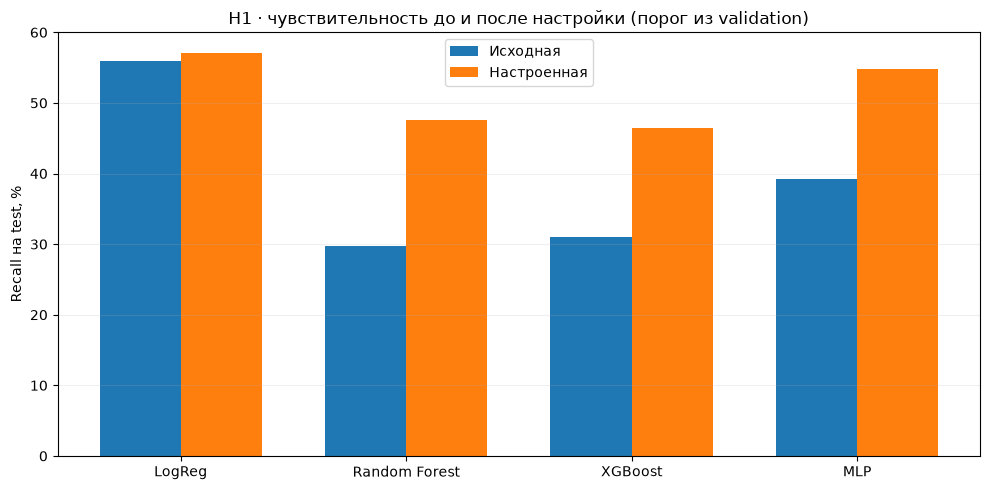

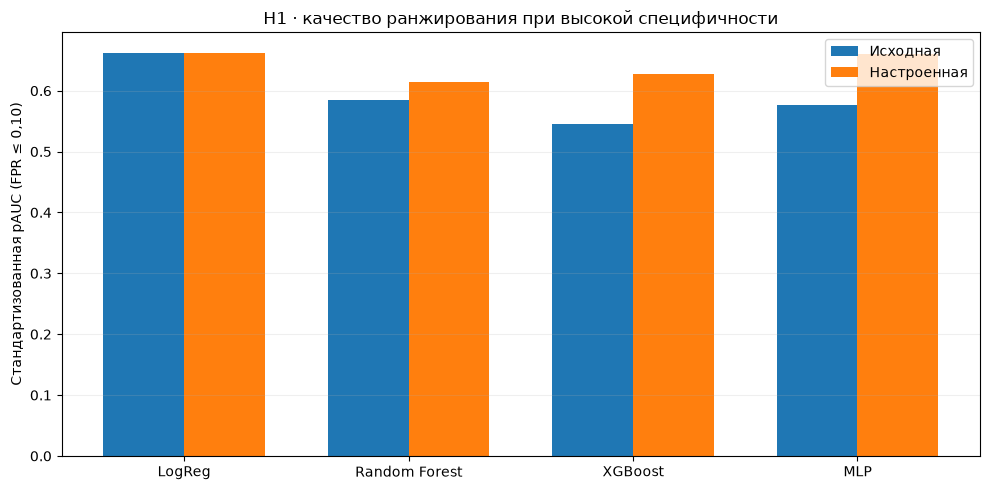

In [71]:
names = list(initial_models)
x = np.arange(len(names))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, [100 * test_metrics[f'{name} · исходная']['recall'] for name in names],
       width=width, label='Исходная')
ax.bar(x + width/2, [100 * test_metrics[f'{name} · настроенная']['recall'] for name in names],
       width=width, label='Настроенная')
ax.set_xticks(x, ['LogReg', 'Random Forest', 'XGBoost', 'MLP'])
ax.set_ylabel('Recall на test, %')
ax.set_title('H1 · чувствительность до и после настройки (порог из validation)')
ax.legend()
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2,
       [test_metrics[f'{name} · исходная']['pauc_standardized_fpr_0_10'] for name in names],
       width=width, label='Исходная')
ax.bar(x + width/2,
       [test_metrics[f'{name} · настроенная']['pauc_standardized_fpr_0_10'] for name in names],
       width=width, label='Настроенная')
ax.set_xticks(x, ['LogReg', 'Random Forest', 'XGBoost', 'MLP'])
ax.set_ylabel('Стандартизованная pAUC (FPR ≤ 0,10)')
ax.set_title('H1 · качество ранжирования при высокой специфичности')
ax.legend()
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

## 10. Сохранение результатов

Сохраняем компактные CSV и JSON, чтобы использовать полученные параметры и показатели при дальнейшем анализе. `results/` уже существует в репозитории. Отдельные файлы **не содержат персональных данных** — только агрегированные результаты и настройки эксперимента.

Для коммита можно включить эти три файла вместе с ноутбуком, если он выполнен до конца.

In [34]:
results_dir = PROJECT_ROOT / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

report.to_csv(results_dir / 'h1_test_metrics.csv', encoding='utf-8')
comparison.to_csv(results_dir / 'h1_paired_comparison.csv', encoding='utf-8')

experiment_config = {
    'n': N,
    'data_seed': DATA_SEED,
    'split_seed': SPLIT_SEED,
    'model_seed': MODEL_SEED,
    'cv_seed': CV_SEED,
    'cv_folds': N_SPLITS,
    'search_iterations_per_model': N_ITER,
    'selection_metric': 'standardized_partial_roc_auc_fpr_le_0.10',
    'min_validation_specificity': MIN_SPECIFICITY,
    'selected_parameters': {name: selected_params[name] for name in initial_models},
    'versions': {
        'python': sys.version.split()[0],
        'numpy': np.__version__,
        'pandas': pd.__version__,
        'scikit_learn': sklearn.__version__,
        'xgboost': xgboost.__version__,
    },
}
with (results_dir / 'h1_selected_params.json').open('w', encoding='utf-8') as f:
    json.dump(experiment_config, f, ensure_ascii=False, indent=2, default=str)

print('Сохранены:')
for fname in ['h1_test_metrics.csv', 'h1_paired_comparison.csv', 'h1_selected_params.json']:
    print(' ', results_dir / fname)

Сохранены:
  /Users/dyadyundanil/Documents/lung-cancer-ml-study/results/h1_test_metrics.csv
  /Users/dyadyundanil/Documents/lung-cancer-ml-study/results/h1_paired_comparison.csv
  /Users/dyadyundanil/Documents/lung-cancer-ml-study/results/h1_selected_params.json


## 11. Итог по гипотезе H1

Сначала изучаем **разницу между исходной и настроенной моделью** по всем четырём алгоритмам. Если настроенные модели не улучшились или выигрыш неустойчив, это **нормальный результат проверки гипотезы**, а не ошибка эксперимента.

Обязательно учитываем: (1) величину и интервал Δ Recall; (2) изменение Specificity(test); (3) Δ pAUC, AP и Brier; (4) небольшое число положительных случаев; (5) сильные ограничения контрольного сценария, где PLCOm2012 задаёт истинную вероятность.

**Статус H1 после этого ноутбука:** предварительная проверка **на одной новой синтетической выборке**. Для убедительного вывода понадобится проверка устойчивости на нескольких независимых генерациях (H4); использование текущего test для нового выбора параметров запрещено.

<!-- h1-results-comment:H1 -->
### Промежуточное заключение по H1

**Статус: предварительно поддерживается данными (не отвергается).** Подбор гиперпараметров улучшил показатели Random Forest, XGBoost и MLP на независимой тестовой выборке; для Logistic Regression убедительного выигрыша не наблюдается. Эффект зависит от алгоритма, а повышение Recall следует рассматривать вместе со специфичностью и качеством ранжирования. **Окончательное заключение пока преждевременно:** эксперимент проведён на одной синтетической генерации, поэтому устойчивость эффекта предстоит проверить при повторениях с разными seed (H4).
